# Regressione logistica: studenti e depressione

**Obiettivo.** Costruire un classificatore che stimi la probabilità che uno studente sia depresso a partire da alcune sue caratteristiche, seguendo il flusso visto nelle lezioni (Lezione 02 per la preparazione dei dati, Lezione 04 per modello e metriche):

1. scegliere i predittori sulla base dell'analisi esplorativa (notebook "juno's story");
2. costruire `df_model`;
3. dividere in train e test;
4. standardizzazione delle numeriche (`StandardScaler`), stimata solo sul train;
5. modello interpretativo (statsmodels) e modello predittivo (scikit-learn), con grid search;
6. scelta della soglia ragionando sul tipo di errore che costa di più;
7. valutazione con matrice di confusione e metriche.

### Librerie e parametri
Come nelle lezioni: pandas e numpy per i dati, matplotlib e seaborn per i grafici, scikit-learn per modelli e metriche (importata come `skl_metr`). In più **statsmodels**, che non è nelle lezioni: lo usiamo solo per leggere coefficienti, p-value e odds ratio. Il `RANDOM_STATE` fisso garantisce gli stessi sottocampioni a ogni esecuzione.

In [37]:
import os
import pickle
import warnings
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import sklearn.metrics as skl_metr

warnings.filterwarnings("ignore")
pd.set_option("display.width", 1000)
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: "%.3f" % x)

FILE_CSV = "/Users/ale/Desktop/CRIF SETTIMANA 3/Student_Depression_Dataset.csv"
OUT_DIR = "models"        # dove salvare scaler, modello e dizionari
RANDOM_STATE = 42         # seed fisso: stessi sottocampioni a ogni run
os.makedirs(OUT_DIR, exist_ok=True)

### Dati, chiave e target
Il dataset non ha una chiave: ne costruiamo una (`student_id`), come nel notebook degli iris. La regressione logistica vuole un target numerico: trasformiamo `Depression` in `y` (1 = depresso, 0 = non depresso). Circa il 27% degli studenti è depresso: classi sbilanciate ma gestibili.

In [38]:
df = pd.read_csv(FILE_CSV)
df["student_id"] = ["S" + f"{k}".rjust(4, "0") for k in range(len(df))]   # chiave univoca
df["y"] = df["Depression"].map({"No": 0, "Yes": 1})                       # target 0/1

print(df.shape)
print(df["student_id"].nunique() == len(df))      # la chiave deve essere univoca
print(df["y"].value_counts(normalize=True))       # ~73% / 27%

(4464, 15)
True
y
0   0.731
1   0.269
Name: proportion, dtype: float64


### Scelta delle variabili
La scelta si basa sui risultati dell'analisi esplorativa (notebook "juno's story"): chi-quadro con correzione di Bonferroni per le categoriche, Mann-Whitney per le numeriche, più la forza dell'effetto (V di Cramér, A). Le variabili escluse e il perché sono nei commenti. Le altre le dividiamo per tipo, perché ogni tipo richiede un trattamento diverso (binarie, categoriche, numeriche).

In [39]:
# 2) SCELTA DELLE VARIABILI (in base ai risultati dell'EDA, notebook "juno's story")
# DENTRO:
#  - Relationship_status (V=0.26), friend_circle (V=0.10): associazioni deboli ma significative
#  - Family_background, Home_division (V~0.09): trascurabili ma significative dopo Bonferroni
#  - CGPA: unico numerico con differenza chiara (A=0.56)
#  - Age: significativa dopo Bonferroni (p=0.037), effetto trascurabile
#  - Gender e Cost_without_study: non significative da sole, ma intrecciate con altre variabili:
#    il genere cambia dentro ogni stato di relazione; il costo dipende dalla classe sociale
# FUORI:
#  - Health_condition: separa quasi perfettamente il target (Critical 100%, Good 0%)
#    -> data leakage, il modello "barerebbe"
#  - Marital_status: tolta dall'analisi (si sovrappone a Relationship_status)
#  - Living_style (p corretto=0.132), Current_semester (p corretto=0.983): nessuna differenza affidabile
COL_CAT = ["Relationship_status", "Family_background", "Home_division", "Living_style"]   # 3 o piu' valori -> dummy
COL_NUM = ["CGPA", "Cost_without_study", "Age", "Current_semester"]                           # numeriche -> scaler

### Costruzione di `df_model` (prima dello split)
Qui facciamo solo trasformazioni **a regola fissa**, che non imparano nulla dai dati (es. "Male = 1"). Per questo si possono fare sul dataframe intero senza far trapelare informazione dal test, e `df_model` resta disponibile per qualsiasi altro modello.

Non costruiamo variabili nuove: usiamo quelle dell'analisi esplorativa così come sono. Le idee provate (single senza amici, CGPA basso, raggruppare Dhaka e Sylhet) non erano necessarie o non erano sostenute dall'analisi esplorativa, e sono state scartate.

In [40]:
# 3) COSTRUZIONE DEL DATAFRAME DEL MODELLO (fuori dallo split, sul df intero)
# Qui metto SOLO trasformazioni "a regola fissa", che non imparano nulla dai dati
# (es. "Male = 1"). Per questo si possono fare prima dello split senza far
# trapelare informazione dal test. Il risultato, df_model, resta disponibile
# per qualsiasi altra analisi o modello.
# Le trasformazioni che stimano parametri dai dati (mediana e IQR dello scaler)
# vanno invece fatte DOPO lo split, solo sul train.
def costruisci_variabili(d):
    X = pd.DataFrame(index=d.index)

    # 3a) chiave e target
    X["student_id"] = d["student_id"]
    X["y"] = d["Depression"].map({"No": 0, "Yes": 1})

    # 3b) binarie: una colonna 0/1
    X["male"] = (d["Gender"] == "Male").astype(int)
    X["no_friends"] = (d["friend_circle"] == "No").astype(int)

    # 3c) categoriche con piu' di 2 valori: copiate qui, diventano dummy subito sotto
    X["Relationship_status"] = d["Relationship_status"]
    X["Family_background"] = d["Family_background"]
    X["Home_division"] = d["Home_division"]
    X['Living_style'] = d['Living_style']

    # 3d) numeriche originali (scaling dopo lo split)
    X["CGPA"] = d["CGPA"]
    X["Cost_without_study"] = d["Cost_without_study"]
    X["Age"] = d["Age"]
    X['Current_semester'] = d['Current_semester']

    return X

df_model = costruisci_variabili(df)

#### Dummy per le categoriche
Le variabili con 3 o più valori non si possono scrivere come 1, 2, 3 (il modello penserebbe a un ordine che non esiste): si crea una colonna 0/1 per categoria. Con `drop_first=True` si toglie una categoria, che diventa il **riferimento** con cui si confrontano le altre; senza, le colonne si sommerebbero sempre a 1 (multicollinearità perfetta).

In [41]:
# 3f) DUMMY per le categoriche con piu' di 2 valori
# drop_first=True toglie una categoria per variabile (il "riferimento"):
#   Relationship_status -> riferimento = Complicated (prima in ordine alfabetico)
#   Family_background  -> riferimento = Lower Middle class
#   Home_division      -> riferimento = Barisal
# Senza drop_first le colonne si sommerebbero sempre a 1 (multicollinearita' perfetta).
# Fatte sul df intero, train e test hanno gia' le stesse colonne: niente reindex.
df_model = pd.get_dummies(df_model, columns=COL_CAT, drop_first=True, dtype=int)

print(df_model.shape)
df_model.head()

(4464, 20)


,student_id,y,male,no_friends,CGPA,Cost_without_study,Age,Current_semester,Relationship_status_In a Relationship,Relationship_status_Single,Family_background_Middle class,Family_background_Rich class,Home_division_Chittagong,Home_division_Dhaka,Home_division_Khulna,Home_division_Mymensingh,Home_division_Rajshahi,Home_division_Rangpur,Home_division_Sylhet,Living_style_Family
0,S0000,1,0,0,3.430,10113,22,8,0,1,1,0,1,0,0,0,0,0,0,0
1,S0001,1,1,0,3.700,13815,19,2,0,1,1,0,1,0,0,0,0,0,0,0
2,S0002,1,1,1,3.280,15450,23,8,0,1,1,0,0,1,0,0,0,0,0,1
3,S0003,0,1,1,3.770,17413,20,2,0,0,1,0,0,1,0,0,0,0,0,1
4,S0004,1,0,1,4.000,16693,21,1,0,1,1,0,0,1,0,0,0,0,0,1


### Train / test split
Dividiamo `df_model` in 80% train e 20% test. `stratify` mantiene la stessa percentuale di depressi nei due campioni (con classi sbilanciate e un test piccolo, il caso potrebbe darci un test con molti più o molti meno depressi del dovuto). Da qui in poi ogni trasformazione che stima dei parametri va fatta **solo sul train**.

In [42]:
# 4) TRAIN / TEST SPLIT
# stratify=y mantiene la stessa % di depressi (26.9%) in train e in test.
df_train, df_test = train_test_split(
    df_model, test_size=0.2, random_state=RANDOM_STATE, stratify=df_model["y"]
)
y_train = df_train["y"]
y_test = df_test["y"]
X_train = df_train.drop(columns=["student_id", "y"]).copy()
X_test = df_test.drop(columns=["student_id", "y"]).copy()

print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())              # devono essere quasi uguali
print(list(X_train.columns))

(3571, 18) (893, 18)
0.26911229347521703 0.2687569988801792
['male', 'no_friends', 'CGPA', 'Cost_without_study', 'Age', 'Current_semester', 'Relationship_status_In a Relationship', 'Relationship_status_Single', 'Family_background_Middle class', 'Family_background_Rich class', 'Home_division_Chittagong', 'Home_division_Dhaka', 'Home_division_Khulna', 'Home_division_Mymensingh', 'Home_division_Rajshahi', 'Home_division_Rangpur', 'Home_division_Sylhet', 'Living_style_Family']


### Standardizzazione delle numeriche
Le numeriche hanno scale molto diverse (`Age` da 17 a 28, `CGPA` da 2,25 a 4, `Cost_without_study` fino a 32.000): le **standardizziamo** con lo `StandardScaler`, che sottrae la media e divide per la deviazione standard, così ognuna ha media 0 e deviazione standard 1.

Serve a due cose: i coefficienti diventano confrontabili (ognuno è l'effetto di **un aumento di una deviazione standard**) e la regolarizzazione della grid search penalizza tutte le variabili allo stesso modo.

Come per ogni trasformazione che stima parametri, lo scaler si stima solo sul train (`fit`) e si applica a train e test (`transform`). Dopo lo scaling controlliamo che il train abbia media 0 e deviazione standard 1; sul test i valori saranno vicini ma non identici, perché usiamo i parametri del train.

In [43]:
# 5) STANDARD SCALER (fit SOLO sul train!)
scaler = StandardScaler()
X_train[COL_NUM] = scaler.fit_transform(X_train[COL_NUM])   # fit + transform sul train
X_test[COL_NUM] = scaler.transform(X_test[COL_NUM])         # solo transform sul test

print("TRAIN (media ~0 e std ~1):")
print(X_train[COL_NUM].agg(["mean", "std"]).T)
print("TEST (vicini a 0 e 1, non identici):")
print(X_test[COL_NUM].agg(["mean", "std"]).T)

# controllo: le numeriche del train sono davvero standardizzate
assert np.allclose(X_train[COL_NUM].mean(), 0, atol=1e-8)
assert np.allclose(X_train[COL_NUM].std(ddof=0), 1, atol=1e-8)

TRAIN (media ~0 e std ~1):
                    mean   std
CGPA               0.000 1.000
Cost_without_study 0.000 1.000
Age                0.000 1.000
Current_semester   0.000 1.000
TEST (vicini a 0 e 1, non identici):
                     mean   std
CGPA                0.015 0.961
Cost_without_study  0.047 1.020
Age                -0.003 1.007
Current_semester   -0.029 0.974


### Modello interpretativo (statsmodels)
`Logit` restituisce coefficienti, p-value e intervalli di confidenza. L'**odds ratio** (`exp(coefficiente)`) si legge così: sopra 1 la variabile aumenta il rischio di depressione, sotto 1 lo riduce. Per le numeriche è riferito a un aumento di una deviazione standard. L'AIC serve a confrontare versioni diverse del modello (più basso = meglio).

Questo modello è **senza pesi e senza regolarizzazione**: è quello da cui leggere gli effetti. Il modello predittivo di scikit-learn (più sotto) usa `class_weight="balanced"`: le sue probabilità sono "gonfiate" e vanno usate solo per ordinare gli studenti, non lette come probabilità reali.

                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                 3571
Model:                          Logit   Df Residuals:                     3552
Method:                           MLE   Df Model:                           18
Date:                Wed, 28 Oct 2026   Pseudo R-squ.:                  0.1187
Time:                        12:02:47   Log-Likelihood:                -1832.7
converged:                       True   LL-Null:                       -2079.7
Covariance Type:            nonrobust   LLR p-value:                 2.005e-93
                                            coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------
const                                    -1.4581      0.293     -4.979      0.000      -2.032      -0.884
male                                     -0.5581  

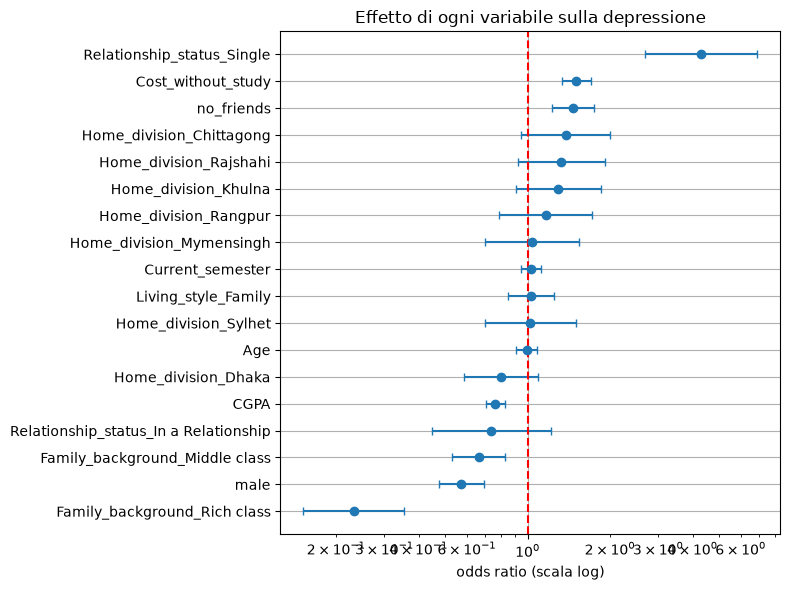

In [44]:
# 6) MODELLO INTERPRETATIVO: statsmodels (coefficienti, p-value, odds ratio)
logit = sm.Logit(y_train, sm.add_constant(X_train)).fit(disp=0)
print(logit.summary())

# Odds ratio = exp(coefficiente). >1 aumenta le probabilita' di depressione, <1 le riduce.
conf = logit.conf_int()
tab_or = pd.DataFrame({
    "odds_ratio": np.exp(logit.params),
    "IC95_basso": np.exp(conf[0]),
    "IC95_alto": np.exp(conf[1]),
    "p_value": logit.pvalues,
}).drop(index="const").sort_values("odds_ratio")
print(tab_or)
print("AIC:", round(logit.aic, 1))        # utile per confrontare versioni del modello (piu' basso = meglio)

fig, ax = plt.subplots(figsize=(8, 6))
ax.errorbar(tab_or["odds_ratio"], range(len(tab_or)),
            xerr=[tab_or["odds_ratio"] - tab_or["IC95_basso"], tab_or["IC95_alto"] - tab_or["odds_ratio"]],
            fmt="o", color="tab:blue", capsize=3)
ax.axvline(1, color="red", ls="--")       # OR = 1 -> nessun effetto
ax.set_yticks(range(len(tab_or)))
ax.set_yticklabels(tab_or.index)
ax.set_xscale("log")
ax.set_xlabel("odds ratio (scala log)")
ax.set_title("Effetto di ogni variabile sulla depressione")
ax.grid(True)
plt.tight_layout()
plt.show()

#### Come leggere i risultati
- **Odds ratio**: sopra 1 la variabile aumenta il rischio, sotto 1 lo riduce, uguale a 1 nessun effetto. Si riferisce agli *odds* (probabilità di essere depresso / probabilità di non esserlo), non alla probabilità: un odds ratio di 2 raddoppia gli odds.
- **Intervallo di confidenza al 95%**: se contiene 1, l'effetto non è chiaramente diverso da zero. Lo stesso vale per un p-value sopra 0,05.
- **A parità delle altre variabili**: ogni effetto è calcolato tenendo fisse tutte le altre, a differenza dell'analisi esplorativa, dove ogni variabile era analizzata da sola.
- **Riferimento delle dummy**: l'odds ratio di una dummy si legge rispetto alla categoria tolta con `drop_first` (`Complicated` per `Relationship_status`, `Lower Middle class` per `Family_background`, `Barisal` per `Home_division`).
- **Numeriche**: standardizzate, quindi l'odds ratio è riferito a un aumento di una deviazione standard.

Esempi (valori di questo modello): `Relationship_status_Single` ha odds ratio 4,27 (intervallo 2,67-6,84): gli odds di depressione dei single sono circa 4 volte quelli dei `Complicated`. `Family_background_Rich class` ha 0,24: gli studenti di classe Rich hanno odds circa un quarto di quelli di classe Lower Middle. `Age` ha 1,00 (p = 0,975): nessun effetto. `Relationship_status_In a Relationship` ha 0,73 ma l'intervallo (0,45-1,21) contiene 1: non è chiaramente diversa da `Complicated`.

### Modello predittivo: grid search
Come in `modelling_TEST`, iteriamo sui parametri con `product` e salviamo i risultati di ogni combinazione. I parametri della regressione logistica sono:

- **`C`**: l'inverso della forza di regolarizzazione. Valori piccoli = modello più "frenato" (coefficienti più piccoli), valori grandi = modello libero di adattarsi ai dati (rischio di overfitting);
- **`penalty`**: il tipo di regolarizzazione. `l1` può azzerare del tutto i coefficienti delle variabili inutili, `l2` li riduce soltanto.

`class_weight="balanced"` dà più peso agli errori sui depressi (la classe rara): altrimenti il modello tende a rispondere sempre "No".

Per ogni combinazione guardiamo l'AUC in cross-validation a 5 fold (calcolata solo sul train) e, come nel corso, l'AUC su train e su test: **il modello migliore non è solo quello con il valore più alto, ma anche quello con poco scarto tra train e test** (l'overfitting).

In [45]:
# 7) GRID SEARCH sulla regressione logistica
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

C_list = [0.01, 0.1, 1, 10]
penalty_list = ["l1", "l2"]

righe = []
for idx, (C, pen) in enumerate(product(C_list, penalty_list)):
    mod = LogisticRegression(C=C, penalty=pen, solver="liblinear", class_weight="balanced",
                             random_state=RANDOM_STATE)
    auc_cv = cross_val_score(mod, X_train, y_train, cv=cv, scoring="roc_auc").mean()
    mod.fit(X_train, y_train)
    auc_train = skl_metr.roc_auc_score(y_train, mod.predict_proba(X_train)[:, 1])
    auc_test = skl_metr.roc_auc_score(y_test, mod.predict_proba(X_test)[:, 1])
    righe.append([f"{pen}_{C}", C, pen, auc_cv, auc_train, auc_test, auc_train - auc_test])

df_grid = pd.DataFrame(righe, columns=["combo", "C", "penalty", "AUC cv", "AUC train", "AUC test", "scarto train-test"])
df_grid = df_grid.sort_values("AUC cv", ascending=False).reset_index(drop=True)
df_grid.style.background_gradient(subset=["AUC cv", "AUC train", "AUC test"], vmin=0.6, vmax=0.75).format(precision=3, subset=["AUC cv", "AUC train", "AUC test", "scarto train-test"])

,combo,C,penalty,AUC cv,AUC train,AUC test,scarto train-test
0,l1_0.1,0.100000,l1,0.721,0.729,0.664,0.064
1,l2_1,1.000000,l2,0.720,0.732,0.670,0.062
2,l1_1,1.000000,l1,0.720,0.732,0.669,0.062
3,l1_10,10.000000,l1,0.720,0.732,0.670,0.062
4,l2_10,10.000000,l2,0.720,0.732,0.669,0.062
5,l2_0.1,0.100000,l2,0.719,0.730,0.669,0.061
6,l2_0.01,0.010000,l2,0.714,0.723,0.664,0.059
7,l1_0.01,0.010000,l1,0.687,0.687,0.618,0.069


Scegliamo la combinazione con l'AUC in cross-validation più alta. Quasi tutte le combinazioni sono equivalenti (AUC in cross-validation circa 0,72): il modello non è sensibile a questi parametri e il limite sta nei dati, non nella regolarizzazione. Peggiora solo la combinazione più "frenata" (`l1` con `C = 0,01`), che azzera troppi coefficienti.

In [46]:
best = df_grid.iloc[0]
print(best)

model = LogisticRegression(C=best["C"], penalty=best["penalty"], solver="liblinear",
                           class_weight="balanced", random_state=RANDOM_STATE)
model.fit(X_train, y_train)

combo                l1_0.1
C                     0.100
penalty                  l1
AUC cv                0.721
AUC train             0.729
AUC test              0.664
scarto train-test     0.064
Name: 0, dtype: object


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'l1'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",np.float64(0.1)
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`Lo

### Scelta della soglia: quale errore costa di più?
Il modello restituisce una probabilità; la **soglia** decide da quando diciamo "depresso". Alzando la soglia segnaliamo meno studenti (più sicuri: sale la precision, scende la recall); abbassandola ne segnaliamo di più (sale la recall, scende la precision). Come nel corso, la scelta dipende dallo **scenario**:

- **S1, intervento limitato e costoso** (es. colloquio individuale con uno psicologo, con pochi posti): vogliamo che chi viene segnalato sia davvero depresso. Conta la **precision**, quindi una soglia alta.
- **S2, screening a basso costo** (es. un questionario di approfondimento per chiunque risulti a rischio): non vogliamo perdere nessun caso, anche a costo di falsi allarmi. Conta la **recall**, quindi una soglia bassa.
- **Scenario ibrido**: servono entrambe. Si usa l'**f-score** (o il phi-score), che bilancia precision e recall.

Qui scegliamo la soglia dello scenario ibrido: quella che massimizza l'f-score. Va scelta sul **train**, con predizioni fuori-campione (`cross_val_predict`): scegliendola guardando il test, questo non sarebbe più indipendente. La tabella permette di leggere anche le soglie per S1 e S2.

In [47]:
# 8) SCELTA DELLA SOGLIA (sul train, MAI sul test)
p_cv = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

righe = []
for t in np.arange(0.05, 0.96, 0.01):
    pred = (p_cv >= t).astype(int)
    righe.append([t, skl_metr.precision_score(y_train, pred), skl_metr.recall_score(y_train, pred),
                  skl_metr.f1_score(y_train, pred), skl_metr.matthews_corrcoef(y_train, pred)])
tab_soglie = pd.DataFrame(righe, columns=["soglia", "precision", "recall", "f-score", "phi-score"])

# mostro una riga ogni 0.05
tab_soglie[(tab_soglie["soglia"] * 100).round().astype(int) % 5 == 0].reset_index(drop=True)

,soglia,precision,recall,f-score,phi-score
0,0.050,0.269,1.000,0.424,0.000
1,0.100,0.270,0.999,0.425,0.030
2,0.150,0.281,0.995,0.438,0.121
3,0.200,0.304,0.988,0.465,0.208
4,0.250,0.322,0.968,0.483,0.244
5,0.300,0.339,0.937,0.498,0.268
6,0.350,0.349,0.897,0.502,0.269
7,0.400,0.363,0.861,0.510,0.281
8,0.450,0.374,0.814,0.513,0.281
9,0.500,0.394,0.747,0.516,0.288


In [ ]:
SOGLIA = round(float(tab_soglie.loc[tab_soglie["f-score"].idxmax(), "soglia"]), 2)   # scenario ibrido: massimo f-score
print("Soglia scelta (scenario ibrido):", SOGLIA)

# prob = probabilita' del modello, prediction = classe predetta con la soglia scelta
df_train["prob (logistica)"] = model.predict_proba(X_train)[:, 1]
df_test["prob (logistica)"] = model.predict_proba(X_test)[:, 1]
df_train["prediction (logistica)"] = (df_train["prob (logistica)"] >= SOGLIA).astype(int)
df_test["prediction (logistica)"] = (df_test["prob (logistica)"] >= SOGLIA).astype(int)

# controllo: le colonne create, per i primi studenti del test
df_test[["student_id", "y", "prob (logistica)", "prediction (logistica)"]].head(10)

### Valutazione sul test: matrice di confusione e metriche
Come in Lezione 04: la **matrice di confusione** è la tabella pivot con la classe vera in riga e quella predetta in colonna; più è popolata sulla diagonale principale, meglio funziona il modello. Poi calcoliamo le metriche una per una:

- **accuracy**: classificazioni corrette su tutti i casi. Va letta con il benchmark "rispondo sempre No" (circa 73%): con classi sbilanciate può ingannare;
- **precision**: quando il modello dice "depresso", quante volte ha ragione (problema in S1);
- **recall**: quanti dei depressi veri riconosce (problema in S2);
- **f-score**: media armonica di precision e recall;
- **phi-score** (coefficiente di Matthews): considera tutta la matrice, ed è più robusto con classi sbilanciate.

Il test si guarda una volta sola, a fine lavoro. Se i valori sul train sono molto migliori di quelli sul test c'è overfitting.

In [49]:
# 9) VALUTAZIONE SULLA REGRESSIONE LOGISTICA
df_pivot = pd.pivot_table(df_test, index="y", columns="prediction (logistica)",
                          values="student_id", aggfunc="count", fill_value=0)
df_pivot.style.background_gradient(vmin=0, vmax=400).format(precision=0)

prediction (logistica),0,1
y,,
0,332,321
1,70,170


In [50]:
metriche = {
    "accuracy": skl_metr.accuracy_score,
    "precision": skl_metr.precision_score,
    "recall": skl_metr.recall_score,
    "f-score": skl_metr.f1_score,
    "phi-score": skl_metr.matthews_corrcoef,
}

df_metriche = pd.DataFrame({
    "train": {k: f(y_train, df_train["prediction (logistica)"]) for k, f in metriche.items()},
    "test": {k: f(y_test, df_test["prediction (logistica)"]) for k, f in metriche.items()},
})
df_metriche.loc["AUC"] = [skl_metr.roc_auc_score(y_train, df_train["prob (logistica)"]),
                          skl_metr.roc_auc_score(y_test, df_test["prob (logistica)"])]
print(df_metriche)
print("Accuracy 'rispondo sempre No':", round(1 - y_test.mean(), 3))      # benchmark

           train  test
accuracy   0.608 0.562
precision  0.387 0.346
recall     0.785 0.708
f-score    0.519 0.465
phi-score  0.292 0.193
AUC        0.729 0.664
Accuracy 'rispondo sempre No': 0.731


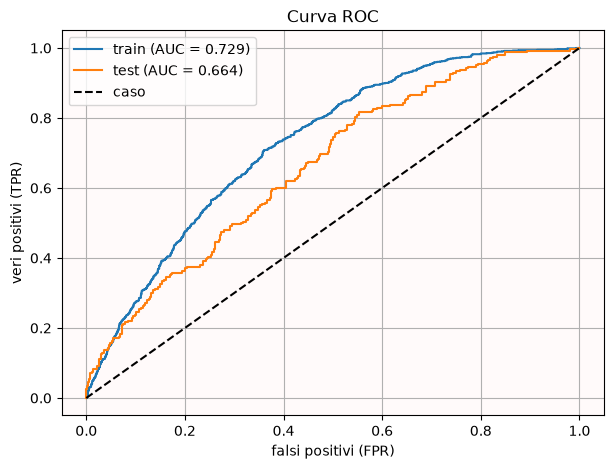

In [51]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(7, 5))
for nome, y, p in [("train", y_train, df_train["prob (logistica)"]), ("test", y_test, df_test["prob (logistica)"])]:
    fpr, tpr, _ = skl_metr.roc_curve(y, p)
    ax.plot(fpr, tpr, label=f"{nome} (AUC = {skl_metr.roc_auc_score(y, p):.3f})")
ax.plot([0, 1], [0, 1], "k--", label="caso")
ax.set_xlabel("falsi positivi (FPR)")
ax.set_ylabel("veri positivi (TPR)")
ax.set_title("Curva ROC")
ax.set_facecolor("snow")
ax.legend()
ax.grid()
plt.show()

### Salvataggio
Come nelle lezioni, salviamo tutto ciò che serve per riapplicare il modello a dati nuovi: scaler, modello, elenco delle colonne e soglia.

In [52]:
# 10) SALVATAGGIO (per riapplicare tutto in produzione)
pickle.dump(scaler, open(os.path.join(OUT_DIR, "scaler_logistica.pkl"), "wb"))
pickle.dump(model, open(os.path.join(OUT_DIR, "modello_logistica.pkl"), "wb"))
pickle.dump(list(X_train.columns), open(os.path.join(OUT_DIR, "colonne_logistica.pkl"), "wb"))
pickle.dump(SOGLIA, open(os.path.join(OUT_DIR, "soglia_logistica.pkl"), "wb"))